# Hybrid OCT Despeckling — PnP-ADMM with a TGV² Model Step and a Non-Local-Means Denoiser

A hybrid built from the five papers of the mini-project, evaluated on the Duke SD-OCT 2012 set
(`Sparsity_SDOCT_DATASET_2012`, Fang et al. 2012).

| Piece of the hybrid | Taken from | What it contributes |
|---|---|---|
| **TGV² regulariser** (x-step of ADMM) | Duan et al. 2016 (TGV decomposition) | *Local geometry prior*: retinal layers are piecewise-smooth ramps with sharp boundaries; TGV allows ramps without TV's staircasing |
| **Non-local means** (v-step of ADMM, and stage 2) | Chen & Gao 2022 (NLM framework) | *Non-local self-similarity prior*: the same layer texture repeats along the B-scan, so it can be averaged |
| **Automatic noise level σ̂** (GLCM-entropy block + Immerkaer mask) | Zhang et al. 2022 (sparse denoising) | Every strength parameter is a multiple of σ̂, so parameters tuned on 2 images transfer to the others |
| **Intensity-adaptive strength map s(x)** | Bernardes et al. 2010 (adaptive complex diffusion, κ from local intensity) | Smooth hard in the dark vitreous/choroid, gently on bright thin layers |
| **Reference-based tuning on held-in images only** | replaces the PSO-on-noisy-PSNR loop of Subhedar et al. 2023 | Parameters are picked on 2 images against their averaged reference, results are reported on the other 15 |

**Why plug-and-play ADMM?** The problem is split as $\min_x \tfrac12\|x-z\|^2 + \text{TGV}(x) + R_{\text{NLM}}(x)$.
ADMM alternates between (i) a *model step* — a TGV denoise pulled towards the data $z$, and (ii) a *prior step* —
"denoise the current estimate" with NLM. NLM has no closed-form regulariser $R$, but PnP only ever needs its
proximal step, and *a denoiser is exactly a proximal step*. The two priors fail in different places (TGV flattens
texture, NLM leaves blotches when patches are matched on speckle), and ADMM forces a consensus that satisfies both.
A bonus: each ADMM pass feeds NLM a cleaner image, so its patch matching gets more reliable every iteration.

```
noisy z ─► σ̂ (Zhang)  ─► s(x) (Bernardes) ─► TGV pilot ─┐
                                                         ▼
          ┌──────────── PnP-ADMM, ρ ↑ each pass ─────────────────┐
          │ x ← TGV²-prox of (z + ρ(v−u))/(1+ρ)   [model + data]   │
          │ v ← NLM_{h_k·s(x)}(x + u)              [self-similarity]│
          │ u ← u + x − v                           [consensus]     │
          └───────────────────────────────────────────────────────┘
                                                         ▼
          stage 2 (optional): NLM weights from v, averaging of the *raw* z  ─► blend  β·stage2 + (1−β)·v
```

Stage 2 is the BM3D "second step" idea: patch similarity measured on a clean estimate, averaging done on the raw data,
so the result keeps more fine texture. β trades PSNR against SSIM and is tuned like every other parameter.

Outputs are written to `outputs/`: every (image, method, parameter) row goes to `results_log.csv`, each run appends
its headline numbers to `run_history.csv`, and `RESULTS.md` holds the latest tables.

In [1]:
import os
import time
import json
import threading
import datetime as dt
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import pywt
import scipy.io as sio
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import uniform_filter, gaussian_filter, convolve, gaussian_laplace
from scipy.stats import wilcoxon
from skimage.feature import graycomatrix
from skimage.metrics import structural_similarity
from tqdm.auto import tqdm

try:
    import bm3d                     # optional baseline: pip install bm3d
    HAVE_BM3D = True
except ImportError:
    HAVE_BM3D = False
BM3D_LOCK = threading.Lock()        # the BM3D binary is not thread-safe; it is multi-threaded internally anyway
print("BM3D baseline available:", HAVE_BM3D)

BM3D baseline available: True


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Configuration

All strengths are **normalised by the estimated noise level σ̂** of each B-scan (e.g. NLM uses $h = h_f\,\hat\sigma$,
TGV uses $\alpha_1 = a\,\hat\sigma$). The grids below are run on **every** image and logged; tuning then just *selects*
the grid value with the best mean PSNR (or SSIM) on `TUNE_IMAGES`, and all tables report the 15 held-out images.

In [2]:
DUKE_DIR = Path(os.environ.get("OCT_DUKE_DIR", "../Wavelet_Transform/Sparsity_SDOCT_DATASET_2012"))
OUT_DIR = Path("outputs")
TUNE_IMAGES = ["Image 1", "Image 2"]           # parameters are selected on these only
DEMO_IMAGES = ["Image 5", "Image 9"]           # held-out cases used for the visual comparison
USE_CACHE = True                               # reuse outputs/results_log.csv instead of recomputing
N_WORKERS = min(4, os.cpu_count() or 1)        # images processed in parallel threads (numpy releases the GIL)
MAX_VAL = 255.0

# --- baselines: grids of normalised strengths -------------------------------------------------------
NLM_PATCH, NLM_SEARCH = 7, 21
NLM_GRID = [0.8, 1.0, 1.2, 1.4]                # h = h_f * σ̂  (mean squared patch distance in the exponent)
TGV_GRID = [0.75, 1.0, 1.5, 2.0]               # α1 = a * σ̂,  α0 = 2 α1
TGV_ITERS = 500
BM3D_GRID = [1.0, 1.3, 1.6, 2.0]               # σ_BM3D = c * σ̂

# --- hybrid ------------------------------------------------------------------------------------------
PILOT_A = 1.0                                  # TGV strength of the pilot (also the ADMM model step)
GNLM_GRID = [0.2, 0.3, 0.45, 0.6]              # H2 baseline: TGV pilot -> guided NLM, h = h_f * σ̂
PNP = dict(a_tgv=1.0, h0=0.6, h_decay=0.7, h_min=0.2, rho0=1.0, rho_growth=1.5, n_outer=6, tgv_iters=100)
GAMMA = 0.5                                    # exponent of the intensity-adaptive strength map (0 = off)
STAGE2_H = 0.3                                 # stage-2 guided NLM strength
BETA_GRID = [0.0, 0.25, 0.5, 0.75, 1.0]        # blend: β * stage2 + (1 - β) * PnP output

# --- main selection rule: weighted score of per-image min-max normalised PSNR, SSIM, EPI ----------------
SCORE_WEIGHTS = {"PSNR": 1 / 3, "SSIM": 1 / 3, "EPI": 1 / 3}   # fixed before looking at held-out results

OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "denoised").mkdir(exist_ok=True)
RESULTS_LOG = OUT_DIR / "results_log.csv"
CONFIG = dict(NLM_GRID=NLM_GRID, TGV_GRID=TGV_GRID, TGV_ITERS=TGV_ITERS, BM3D_GRID=BM3D_GRID, PILOT_A=PILOT_A,
              GNLM_GRID=GNLM_GRID, PNP=PNP, GAMMA=GAMMA, STAGE2_H=STAGE2_H, BETA_GRID=BETA_GRID,
              SCORE_WEIGHTS=SCORE_WEIGHTS, TUNE_IMAGES=TUNE_IMAGES, NLM_PATCH=NLM_PATCH, NLM_SEARCH=NLM_SEARCH)

## 2. Dataset

Same loader as the NLM and PSO notebooks: one registered **raw** B-scan and its frame-**averaged** image per case
(the `Distant/` and `Unregistered/` sub-folders of cases 1–2 are not aligned with the raw scan and are skipped), plus
the **MSBTD** result shipped with the dataset.

17 cases from /home/claude/work/Sparsity_SDOCT_DATASET_2012  |  tuning: ['Image 1', 'Image 2']  |  held-out: 15


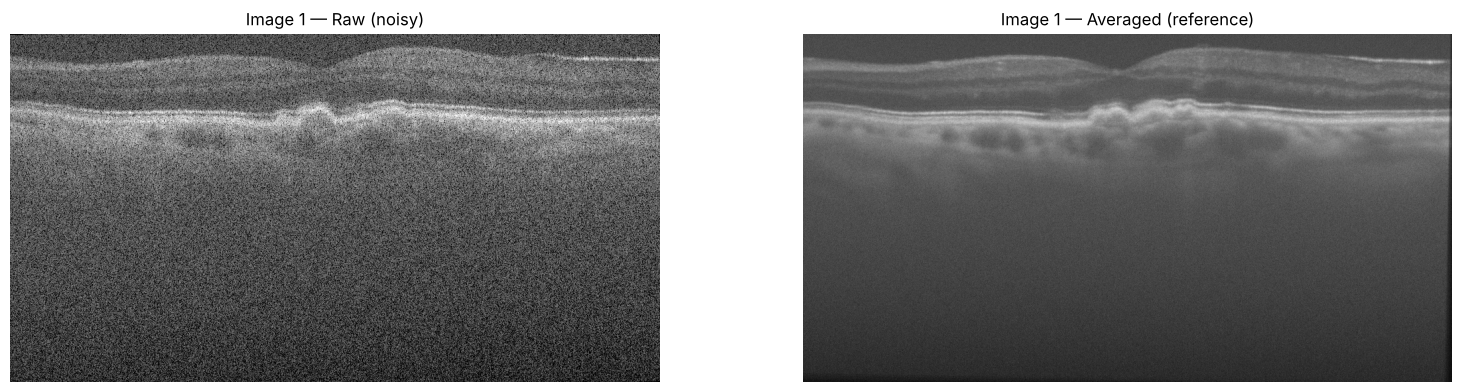

In [3]:
def list_duke(root=DUKE_DIR):
    rows = []
    for case in sorted((d for d in root.iterdir() if d.is_dir() and d.name.isdigit()), key=lambda d: int(d.name)):
        rows.append({"image": f"Image {case.name}",
                     "raw": next(case.glob("*Raw Image.tif")),
                     "ref": next(case.glob("*Averaged Image.tif")),
                     "msbtd": next(case.glob("*MSBTD*.mat"), None)})
    return pd.DataFrame(rows)


def load_gray(path):
    return np.asarray(Image.open(path).convert("L"), dtype=np.float64)


def load_msbtd(path):
    mat = sio.loadmat(path)
    return next(v for k, v in mat.items() if not k.startswith("__")).astype(np.float64)


images = list_duke()
HELD_OUT = [n for n in images["image"] if n not in TUNE_IMAGES]
print(f"{len(images)} cases from {DUKE_DIR.resolve()}  |  tuning: {TUNE_IMAGES}  |  held-out: {len(HELD_OUT)}")
row1 = images.iloc[0]
z1, ref1 = load_gray(row1["raw"]), load_gray(row1["ref"])
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, (t, im) in zip(axes, [("Raw (noisy)", z1), ("Averaged (reference)", ref1)]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=MAX_VAL); ax.set_title(f"Image 1 — {t}"); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Component 1 — automatic noise level σ̂ (Zhang et al. 2022)

**Idea.** Noise is easiest to measure where there is no structure. The B-scan is cut into blocks, the block with
the **lowest GLCM entropy** (most uniform texture) is picked, and **Immerkaer's** mask
$N=\begin{bmatrix}1&-2&1\\-2&4&-2\\1&-2&1\end{bmatrix}$ — the difference of two Laplacians, which cancels any locally
linear signal — gives $\hat\sigma = \sqrt{\pi/2}\,\frac{1}{6(W-2)(H-2)}\sum|I * N|$.

**Why it matters here.** Every strength in this notebook is a multiple of σ̂, so a parameter tuned on two images means
"smooth this many noise-σ's" on every other image. The finest-scale MAD estimate (used in the NLM notebook) is shown for comparison.
Caveat: OCT speckle is spatially correlated, so both estimators measure the fine-scale part of the noise. That is
fine for scaling parameters but not as an absolute noise level.

image,Image 1,Image 2,Image 3,Image 4,Image 5,Image 6,Image 7,Image 8,Image 9,Image 10,Image 11,Image 12,Image 13,Image 14,Image 15,Image 16,Image 17
sigma_zhang,32.93,24.1,25.16,25.47,24.73,23.64,24.8,28.06,25.81,23.14,25.74,22.54,24.4,26.2,30.57,24.85,25.09
sigma_mad,30.39,28.91,28.91,28.91,27.43,27.43,28.17,28.17,28.17,27.43,27.43,27.43,27.43,28.91,28.91,28.91,28.91
block_yx,"(448, 832)","(0, 896)","(0, 0)","(480, 0)","(480, 448)","(0, 832)","(0, 608)","(448, 192)","(416, 864)","(0, 896)","(480, 896)","(0, 352)","(0, 192)","(480, 576)","(448, 256)","(0, 384)","(0, 320)"


correlation between the two estimators: 0.689


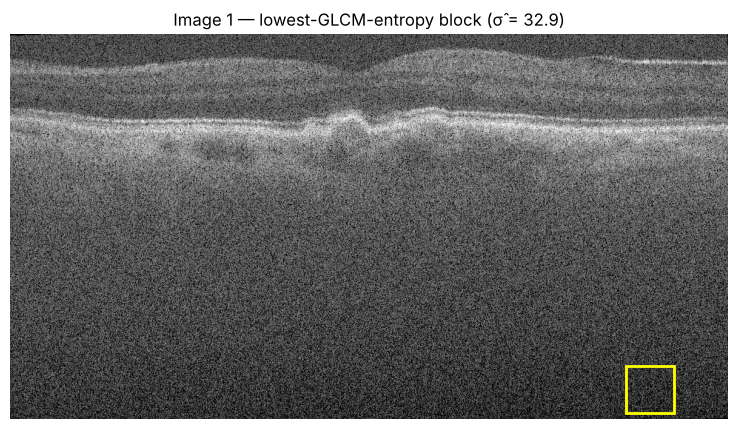

In [4]:
IMMERKAER = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], float)


def sigma_mad(img):
    return np.median(np.abs(pywt.dwt2(img, "haar")[1][2])) / 0.6745


def sigma_immerkaer(block):
    H, W = block.shape
    return np.sqrt(np.pi / 2) / (6 * (W - 2) * (H - 2)) * np.abs(convolve(block, IMMERKAER)[1:-1, 1:-1]).sum()


def glcm_entropy(block, levels=32):
    q = (np.clip(block, 0, 255).astype(np.uint8) // (256 // levels))
    P = graycomatrix(q, [1], [0, np.pi / 2], levels=levels, symmetric=True, normed=True).mean(axis=(2, 3))
    P = P[P > 0]
    return -(P * np.log2(P)).sum()


def sigma_zhang(img, block=64):
    best = None
    for y in range(0, img.shape[0] - block + 1, block // 2):
        for x in range(0, img.shape[1] - block + 1, block // 2):
            b = img[y:y + block, x:x + block]
            if b.std() < 1e-6:
                continue
            e = glcm_entropy(b)
            if best is None or e < best[0]:
                best = (e, y, x)
    _, y, x = best
    return sigma_immerkaer(img[y:y + block, x:x + block]), (y, x)


sig_rows = []
for _, r in images.iterrows():
    z = load_gray(r["raw"])
    s, (by, bx) = sigma_zhang(z)
    sig_rows.append({"image": r["image"], "sigma_zhang": s, "sigma_mad": sigma_mad(z), "block_yx": (by, bx)})
sigma_df = pd.DataFrame(sig_rows).set_index("image")
display(sigma_df.round(2).T)
print("correlation between the two estimators:", np.corrcoef(sigma_df["sigma_zhang"], sigma_df["sigma_mad"])[0, 1].round(3))

by, bx = sigma_df.loc["Image 1", "block_yx"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(z1, cmap="gray", vmin=0, vmax=MAX_VAL)
ax.add_patch(plt.Rectangle((bx, by), 64, 64, fill=False, ec="yellow", lw=2))
ax.set_title(f"Image 1 — lowest-GLCM-entropy block (σ̂ = {sigma_df.loc['Image 1', 'sigma_zhang']:.1f})")
ax.axis("off"); plt.show()

## 4. Component 2 — intensity-adaptive strength map (Bernardes et al. 2010)

Bernardes et al. raise the diffusion threshold κ where the image is dark, so the filter works harder in the vitreous
and backs off in the retina. The same idea is used here as a **gain schedule** for every regulariser:

$$s(x) = \text{clip}\Big(\big(\mu(x)/\text{median}(\mu)\big)^{-\gamma},\ 0.5,\ 2\Big),\qquad \mu = G_{8}*z,$$

and the local strengths become $\alpha_1(x)=a\,\hat\sigma\,s(x)$ (TGV) and $h(x)=h_f\,\hat\sigma\,s(x)$ (NLM).
$\gamma=0$ switches it off. The intuition: one global strength is a compromise. It over-smooths the thin bright layers
and under-smooths the dark background.

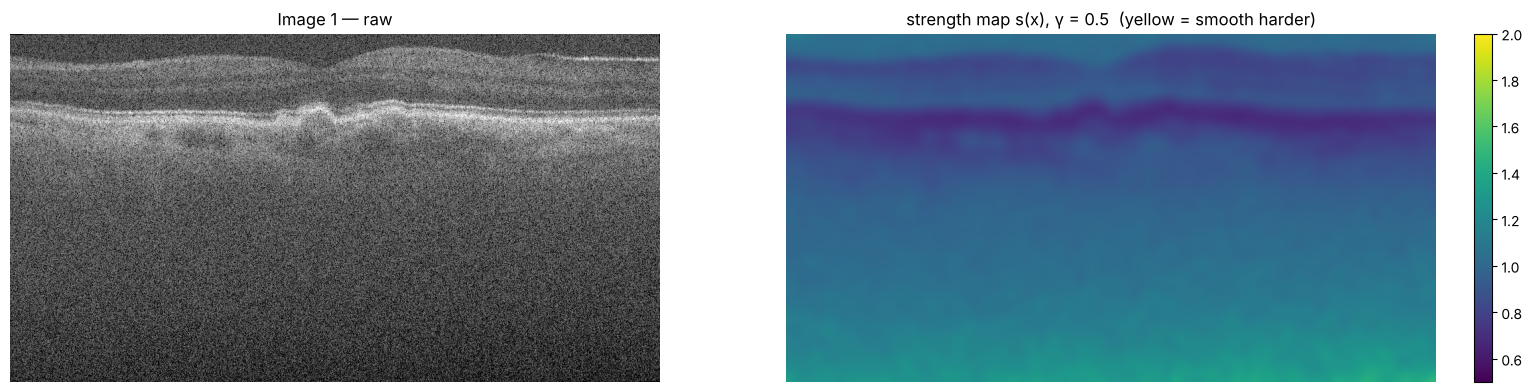

In [5]:
def strength_map(img, gamma, sigma_px=8.0, lo=0.5, hi=2.0):
    if gamma == 0:
        return np.ones_like(img)
    mu = gaussian_filter(img, sigma_px) + 1.0
    return np.clip((mu / np.median(mu)) ** (-gamma), lo, hi)


fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].imshow(z1, cmap="gray", vmin=0, vmax=MAX_VAL); axes[0].set_title("Image 1 — raw")
im = axes[1].imshow(strength_map(z1, GAMMA), cmap="viridis", vmin=0.5, vmax=2)
axes[1].set_title(f"strength map s(x), γ = {GAMMA}  (yellow = smooth harder)")
plt.colorbar(im, ax=axes[1], fraction=0.025)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Component 3 — TGV² denoising (Duan et al. 2016)

$$\min_{u,\,p}\ \tfrac12\|u-f\|_2^2 + \sum_x \alpha_1(x)\,|\nabla u - p|(x) + \sum_x \alpha_0(x)\,|\mathcal E p|(x),
\qquad \alpha_0 = 2\alpha_1 .$$

**Intuition.** $p$ is a "local slope" field. Where the image is a ramp, $p$ follows $\nabla u$ for free, and only
*changes* of slope ($\mathcal E p$, the symmetrised derivative) are paid for. So TGV keeps smooth intensity ramps
across a layer without TV's staircase, and still allows jumps at boundaries.

Duan et al. solve a TGV + Vese–Osher decomposition with split Bregman. Here the TGV² denoising sub-problem is solved
with the **Chambolle–Pock primal–dual** method, which handles the per-pixel $\alpha(x)$ and the warm starts needed
inside ADMM directly. $\nabla$ uses forward differences, $\mathcal E$ backward differences (Neumann boundaries),
step sizes $\tau=\sigma=1/\sqrt{12}$ ($\|K\|^2\le 12$). The adjoint test and energy curve below check the solver.

adjoint test <Au,q> - <u,A^T q>: {'Dx': 0.0, 'Dy': -1.7763568394002505e-14, 'Bx': 1.4210854715202004e-14, 'By': -7.105427357601002e-15}


800 iterations in 13.8s


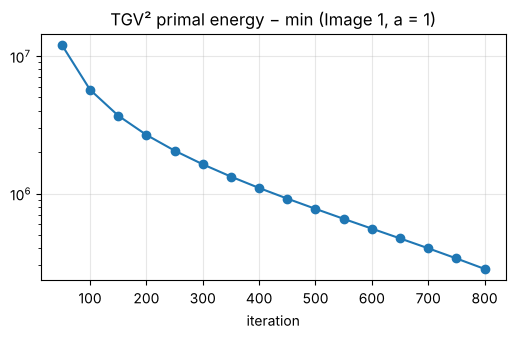

In [6]:
def Dx(u):  g = np.zeros_like(u); g[:, :-1] = u[:, 1:] - u[:, :-1]; return g
def Dy(u):  g = np.zeros_like(u); g[:-1, :] = u[1:, :] - u[:-1, :]; return g
def DxT(q): r = np.zeros_like(q); r[:, 1:] += q[:, :-1]; r[:, :-1] -= q[:, :-1]; return r
def DyT(q): r = np.zeros_like(q); r[1:, :] += q[:-1, :]; r[:-1, :] -= q[:-1, :]; return r
def Bx(u):  g = np.zeros_like(u); g[:, 1:] = u[:, 1:] - u[:, :-1]; return g
def By(u):  g = np.zeros_like(u); g[1:, :] = u[1:, :] - u[:-1, :]; return g
def BxT(q): r = np.zeros_like(q); r[:, 1:] += q[:, 1:]; r[:, :-1] -= q[:, 1:]; return r
def ByT(q): r = np.zeros_like(q); r[1:, :] += q[1:, :]; r[:-1, :] -= q[1:, :]; return r


def tgv_energy(u, px, py, f, a1, a0):
    sym = np.sqrt(Bx(px) ** 2 + By(py) ** 2 + 2 * (0.5 * (By(px) + Bx(py))) ** 2)
    return 0.5 * np.sum((u - f) ** 2) + np.sum(a1 * np.hypot(Dx(u) - px, Dy(u) - py)) + np.sum(a0 * sym)


def tgv_denoise(f, alpha1, alpha0_ratio=2.0, n_iter=300, u0=None, state=None, track_every=0):
    # Chambolle-Pock for TGV^2 with L2 data term; alpha1 may be a per-pixel map. Returns (u, solver state, energies).
    f = f.astype(np.float32)
    a1 = np.asarray(alpha1, np.float32); a0 = a1 * np.float32(alpha0_ratio)
    if state is None:
        u = f.copy() if u0 is None else u0.astype(np.float32).copy()
        px, py, y1, y2, zxx, zyy, zxy = (np.zeros_like(f) for _ in range(7))
    else:
        u, px, py, y1, y2, zxx, zyy, zxy = state
        if u0 is not None:
            u = u0.astype(np.float32).copy()
    ub, pxb, pyb = u.copy(), px.copy(), py.copy()
    tau = sig = np.float32(1 / np.sqrt(12.0))
    energies = []
    for it in range(n_iter):
        # dual ascent + projection onto the alpha-balls
        y1 += sig * (Dx(ub) - pxb); y2 += sig * (Dy(ub) - pyb)
        n = np.maximum(1.0, np.sqrt(y1 * y1 + y2 * y2) / a1); y1 /= n; y2 /= n
        zxx += sig * Bx(pxb); zyy += sig * By(pyb); zxy += sig * 0.5 * (By(pxb) + Bx(pyb))
        n = np.maximum(1.0, np.sqrt(zxx * zxx + zyy * zyy + 2 * zxy * zxy) / a0); zxx /= n; zyy /= n; zxy /= n
        # primal descent (prox of the L2 data term is a weighted average) + over-relaxation
        u_old, px_old, py_old = u, px, py
        u = (u - tau * (DxT(y1) + DyT(y2)) + tau * f) / (1 + tau)
        px = px + tau * (y1 - (BxT(zxx) + ByT(zxy)))
        py = py + tau * (y2 - (ByT(zyy) + BxT(zxy)))
        ub, pxb, pyb = 2 * u - u_old, 2 * px - px_old, 2 * py - py_old
        if track_every and (it + 1) % track_every == 0:
            energies.append((it + 1, float(tgv_energy(u, px, py, f, a1, a0))))
    return u.astype(np.float64), (u, px, py, y1, y2, zxx, zyy, zxy), energies


rng = np.random.default_rng(0)
a_, q_ = rng.standard_normal((30, 40)), rng.standard_normal((30, 40))
print("adjoint test <Au,q> - <u,A^T q>:",
      {A.__name__: float(np.sum(A(a_) * q_) - np.sum(a_ * AT(q_))) for A, AT in [(Dx, DxT), (Dy, DyT), (Bx, BxT), (By, ByT)]})

s1 = sigma_df.loc["Image 1", "sigma_zhang"]
t0 = time.time()
_, _, en = tgv_denoise(z1, 1.0 * s1, n_iter=800, track_every=50)
print(f"800 iterations in {time.time() - t0:.1f}s")
it_, e_ = zip(*en)
plt.figure(figsize=(6, 3.2)); plt.semilogy(it_, np.array(e_) - min(e_) + 1e-3 * min(e_), marker="o")
plt.title("TGV² primal energy − min (Image 1, a = 1)"); plt.xlabel("iteration"); plt.grid(alpha=0.3); plt.show()

## 6. Component 4 — non-local means denoiser (Chen & Gao 2022 framework)

$$\hat v(x)=\frac{\sum_{t\in S(x)} w(x,t)\,f(t)}{\sum_t w(x,t)},\qquad
w(x,t)=\exp\!\Big(-\frac{\overline{(g(x+\Delta)-g(t+\Delta))^2}}{h(x)^2}\Big).$$

Two changes make it usable inside the hybrid:

* **Guided form.** The weights come from a *guide* image $g$, the averaging is applied to $f$. With $g=f$ it is ordinary
  NLM. With $g$ = a clean pilot, patch matching follows anatomy instead of speckle grains (the H2 baseline and stage 2).
* **Per-pixel h** from the strength map, and a guard: when every weight underflows (tiny h on a high-contrast layer),
  the centre weight falls back to 10⁻⁶ so the output keeps the pixel's own value instead of 0/0. Without the guard,
  PnP-ADMM diverged on Image 2 during prototyping.

The **uniform** 7×7 patch kernel is used. In the FCFDS-NLM notebook the uniform kernel beat the FCFDS kernel by
0.34 dB on this dataset (FCFDS's φ_y ≤ 1 shrinks the effective patch to ~3 rows, which makes distances noisy under
heavy speckle). The patch distance is a 7×7 box filter of the squared difference image. Each offset pair (x, x+δ) is
computed once and credited to both pixels, which halves the cost.

In [7]:
def nlm(src, guide=None, h=10.0, patch=NLM_PATCH, search=NLM_SEARCH, hmap=None):
    guide = src if guide is None else guide
    s = search // 2
    H, W = src.shape
    g = np.pad(guide.astype(np.float32), s, mode="reflect")
    f = np.pad(src.astype(np.float32), s, mode="reflect")
    if hmap is None:
        inv = np.full(g.shape, 1 / np.float32(h) ** 2, np.float32)
    else:
        inv = np.pad(1 / (np.float32(h) * hmap.astype(np.float32)) ** 2, s, mode="reflect")
    num, den, wmax = np.zeros_like(f), np.zeros_like(f), np.zeros_like(f)
    Hp, Wp = g.shape
    for dy in range(0, s + 1):
        for dx in range(-s, s + 1):
            if dy == 0 and dx <= 0:
                continue                                  # each unordered offset pair once
            ys, ye, xs, xe = 0, Hp - dy, max(0, -dx), Wp - max(0, dx)
            A = (slice(ys, ye), slice(xs, xe))
            B = (slice(ys + dy, ye + dy), slice(xs + dx, xe + dx))
            d = uniform_filter((g[A] - g[B]) ** 2, patch, mode="nearest")
            wa, wb = np.exp(-d * inv[A]), np.exp(-d * inv[B])
            num[A] += wa * f[B]; den[A] += wa
            num[B] += wb * f[A]; den[B] += wb
            np.maximum(wmax[A], wa, out=wmax[A]); np.maximum(wmax[B], wb, out=wmax[B])
    wmax = np.maximum(wmax, np.float32(1e-6))             # centre weight = max other weight (Buades), with underflow guard
    num += wmax * f; den += wmax
    return (num / den)[s:s + H, s:s + W].astype(np.float64)


t0 = time.time(); _ = nlm(z1, h=1.0 * s1); print(f"NLM on one B-scan: {time.time() - t0:.1f}s")

NLM on one B-scan: 1.7s


## 7. Component 5 — plug-and-play ADMM

Scaled-form ADMM for $\min_x \underbrace{\tfrac12\|x-z\|^2 + \text{TGV}_{\alpha s}(x)}_{f(x)} + \underbrace{R(x)}_{\text{NLM}}$
with the split $x = v$:

1. **Model step** $x \leftarrow \arg\min_x \tfrac12\|x-z\|^2 + \text{TGV}_{\alpha s}(x) + \tfrac\rho2\|x-(v-u)\|^2$.
   Completing the square gives a plain TGV denoise of the target $t=\frac{z+\rho(v-u)}{1+\rho}$ with strength
   $\alpha s(x)/(1+\rho)$. It is solved with 100 warm-started Chambolle–Pock iterations (inexact ADMM).
2. **Prior step** $v \leftarrow \text{NLM}_{h_k s(x)}(x+u)$, clipped to [0, 255]. This is the PnP substitution: the
   proximal map of the unknown prior $R$ is replaced by a denoiser.
3. **Dual step** $u \leftarrow u + x - v$. $u$ accumulates the disagreement between the two priors and pushes them
   towards consensus.

**Continuation.** $\rho_k = 1.5^k\rho_0$ and $h_k = \max(0.7^k h_0, h_{\min})$. Early passes are aggressive. Later
passes trust the consensus more and denoise less, which is the fixed-point convergence recipe of Chan, Wang & Elgendy
(IEEE TCI 2017). The output is $v$ (NLM side). The trace below tracks both iterates on Image 1 against its reference.

**Stage 2.** NLM weights from the PnP output $v$, averaging of the raw $z$, then $\beta\cdot\text{stage2} + (1-\beta)\,v$.

In [8]:
def pnp_admm(z, sig, smap=None, a_tgv=1.0, h0=0.6, h_decay=0.7, h_min=0.2, rho0=1.0, rho_growth=1.5,
             n_outer=6, tgv_iters=100, ref=None):
    smap = np.ones_like(z) if smap is None else smap
    pilot, state, _ = tgv_denoise(z, a_tgv * sig * smap, n_iter=300)          # TGV pilot = initial x and v
    x, v, u = pilot.copy(), pilot.copy(), np.zeros_like(z)
    rho, h, trace = rho0, h0, []
    for k in range(n_outer):
        t = (z + rho * (v - u)) / (1 + rho)
        x, state, _ = tgv_denoise(t, a_tgv * sig * smap / (1 + rho), n_iter=tgv_iters, state=state, u0=x)
        y = x + u
        v = np.clip(nlm(y, h=h * sig, hmap=smap), 0, MAX_VAL)
        u = u + x - v
        rec = {"iter": k + 1, "rho": rho, "h_f": h, "rel_residual": np.linalg.norm(x - v) / np.linalg.norm(v)}
        if ref is not None:
            rec.update(PSNR_x=psnr(ref, x), PSNR_v=psnr(ref, v), SSIM_v=ssim(ref, v))
        trace.append(rec)
        rho *= rho_growth
        h = max(h * h_decay, h_min)
    return v, x, pilot, trace


def stage2(z, v, sig, smap, h=STAGE2_H):
    return nlm(z, guide=v, h=h * sig, hmap=smap)

## 8. Metrics

* **PSNR, SSIM** against the averaged image (same definitions as the NLM notebook: SSIM with a Gaussian window σ = 2).
* **CNR** $=|\mu_s-\mu_b|/\sqrt{\sigma_s^2+\sigma_b^2}$ between the brightest and darkest 11×41 windows of the reference.
* **ENL** $=\mu^2/\sigma^2$ in the most homogeneous bright 11×41 window of the reference (higher = smoother).
* **EPI** (edge preservation index): correlation of the Laplacian-of-Gaussian (σ = 2 px) of output and reference
  (1 = edges kept). A plain 3×3 Laplacian is dominated by the residual speckle of the averaged image (EPI ≈ 0 for
  every method), so edges are compared at layer scale. Heavy blurring is still penalised (Gaussian σ = 8: 0.20, raw: 0.21).

The windows are chosen **once per image from the reference**, are identical for every method, and are never tuned on.
CNR and ENL reward smoothing on their own, so read them next to PSNR/SSIM/EPI.

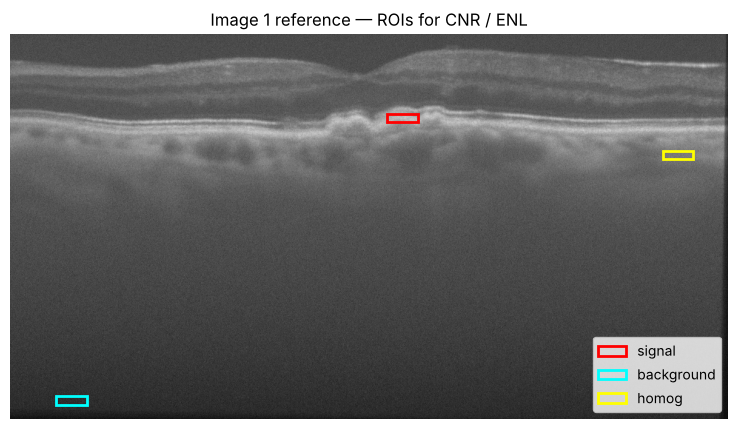

In [9]:
def psnr(ref, img):
    return 20 * np.log10(MAX_VAL / np.sqrt(np.mean((ref - img) ** 2)))


def ssim(ref, img):
    return structural_similarity(ref, img, data_range=img.max() - img.min(), gaussian_weights=True, sigma=2.0,
                                 use_sample_covariance=False)


def make_rois(ref, h=11, w=41, margin=25):
    mu = uniform_filter(ref, (h, w)); sd = np.sqrt(np.maximum(uniform_filter(ref ** 2, (h, w)) - mu ** 2, 0))
    valid = np.zeros_like(ref, bool); valid[margin:-margin, margin:-margin] = True
    def win(idx):
        y, x = np.unravel_index(idx, ref.shape)
        return (slice(y - h // 2, y + h // 2 + 1), slice(x - w // 2, x + w // 2 + 1))
    m = np.where(valid, mu, np.nan)
    bright = win(np.nanargmax(m)); dark = win(np.nanargmin(m))
    cv = np.where(valid & (mu > np.nanpercentile(m, 75)), sd / np.maximum(mu, 1), np.nan)
    return {"signal": bright, "background": dark, "homog": win(np.nanargmin(cv))}


def epi(ref, img, sigma_px=2.0):
    a, b = gaussian_laplace(img, sigma_px), gaussian_laplace(ref, sigma_px)
    a, b = a - a.mean(), b - b.mean()
    return float(np.sum(a * b) / np.sqrt(np.sum(a * a) * np.sum(b * b)))


def all_metrics(ref, img, rois):
    s, b, hmg = img[rois["signal"]], img[rois["background"]], img[rois["homog"]]
    return {"PSNR": psnr(ref, img), "SSIM": ssim(ref, img),
            "CNR": abs(s.mean() - b.mean()) / np.sqrt(s.var() + b.var()),
            "ENL": hmg.mean() ** 2 / max(hmg.var(), 1e-12), "EPI": epi(ref, img)}


rois1 = make_rois(ref1)
fig, ax = plt.subplots(figsize=(10, 5)); ax.imshow(ref1, cmap="gray", vmin=0, vmax=MAX_VAL)
for (k, sl), c in zip(rois1.items(), ["red", "cyan", "yellow"]):
    ax.add_patch(plt.Rectangle((sl[1].start, sl[0].start), sl[1].stop - sl[1].start, sl[0].stop - sl[0].start,
                               fill=False, ec=c, lw=2, label=k))
ax.legend(loc="lower right"); ax.set_title("Image 1 reference — ROIs for CNR / ENL"); ax.axis("off"); plt.show()

### PnP-ADMM trace on Image 1 (tuning image)

What to look for: the residual $\|x-v\|/\|v\|$ should shrink (the priors agree), and PSNR should rise over the first
passes and then flatten instead of drifting.

PnP-ADMM (6 passes) on one B-scan: 26.5s;  TGV pilot PSNR 27.21 dB


,iter,rho,h_f,rel_residual,PSNR_x,PSNR_v,SSIM_v
0,1,1.0000,0.6000,0.0405,27.2510,27.8132,0.5112
1,2,1.5000,0.4200,0.0093,27.8178,27.8268,0.5393
2,3,2.2500,0.2940,0.0078,27.8332,27.8371,0.5511
3,4,3.3750,0.2058,0.0069,27.8455,27.8455,0.5564
4,5,5.0625,0.2000,0.0035,27.8578,27.8647,0.5543
5,6,7.5938,0.2000,0.0040,27.8684,27.8765,0.5520


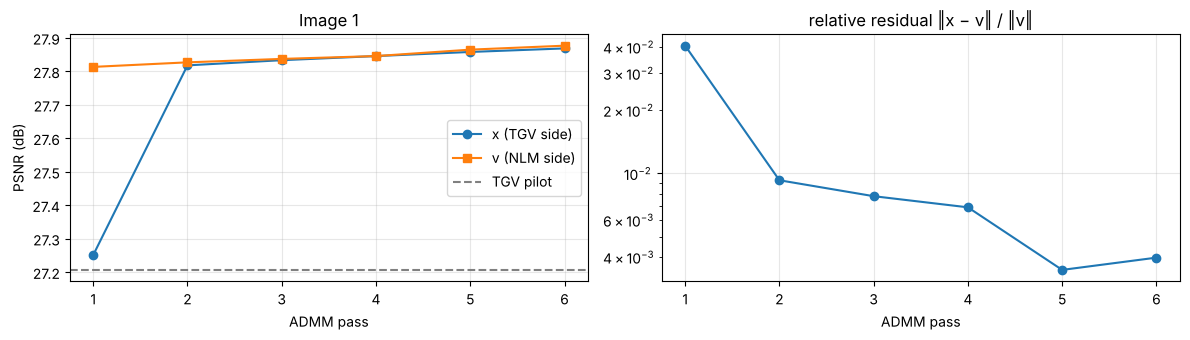

In [10]:
sm1 = strength_map(z1, GAMMA)
t0 = time.time()
v1, x1, pilot1, trace1 = pnp_admm(z1, s1, smap=sm1, ref=ref1, **PNP)
print(f"PnP-ADMM ({PNP['n_outer']} passes) on one B-scan: {time.time() - t0:.1f}s;  TGV pilot PSNR {psnr(ref1, pilot1):.2f} dB")
trace_df = pd.DataFrame(trace1)
display(trace_df.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(trace_df["iter"], trace_df["PSNR_x"], "o-", label="x (TGV side)")
axes[0].plot(trace_df["iter"], trace_df["PSNR_v"], "s-", label="v (NLM side)")
axes[0].axhline(psnr(ref1, pilot1), color="gray", ls="--", label="TGV pilot")
axes[0].set(xlabel="ADMM pass", ylabel="PSNR (dB)", title="Image 1"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].semilogy(trace_df["iter"], trace_df["rel_residual"], "o-")
axes[1].set(xlabel="ADMM pass", title="relative residual ‖x − v‖ / ‖v‖"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "pnp_trace_image1.png", dpi=100); plt.show()
trace_df.to_csv(OUT_DIR / "pnp_trace_image1.csv", index=False)

### PnP sensitivity on the tuning images

The PnP settings in `PNP` were picked by changing one knob at a time on the two tuning images. This cell reruns that
sweep so the choice is documented. It takes a few minutes and is cached in `outputs/pnp_sensitivity.csv`.

In [11]:
SENS_FILE = OUT_DIR / "pnp_sensitivity.csv"
sens_cfgs = [("base", {}, GAMMA), ("a_tgv=0.7", {"a_tgv": 0.7}, GAMMA), ("a_tgv=1.5", {"a_tgv": 1.5}, GAMMA),
             ("h0=0.45", {"h0": 0.45}, GAMMA), ("h0=0.8", {"h0": 0.8}, GAMMA), ("h_min=0.3", {"h_min": 0.3}, GAMMA),
             ("gamma=0", {}, 0.0), ("gamma=1", {}, 1.0)]


def sens_run(job):
    name, over, gamma, img = job
    r = images.set_index("image").loc[img]
    z, ref = load_gray(r["raw"]), load_gray(r["ref"])
    v, *_ = pnp_admm(z, sigma_df.loc[img, "sigma_zhang"], smap=strength_map(z, gamma), **{**PNP, **over})
    return {"config": name, "image": img, "PSNR": psnr(ref, v), "SSIM": ssim(ref, v)}


if USE_CACHE and SENS_FILE.exists():
    sens = pd.read_csv(SENS_FILE)
else:
    jobs = [(n, o, g, img) for n, o, g in sens_cfgs for img in TUNE_IMAGES]
    with ThreadPoolExecutor(N_WORKERS) as ex:
        sens = pd.DataFrame(list(tqdm(ex.map(sens_run, jobs), total=len(jobs), desc="PnP sensitivity")))
    sens.to_csv(SENS_FILE, index=False)
display(sens.groupby("config", sort=False)[["PSNR", "SSIM"]].mean().round(4))

,PSNR,SSIM
config,,
base,28.4114,0.6074
a_tgv=0.7,28.2163,0.6251
a_tgv=1.5,28.4280,0.5706
h0=0.45,28.3774,0.6126
h0=0.8,28.4440,0.5918
h_min=0.3,28.4450,0.5943
gamma=0,28.3844,0.5903
gamma=1,28.1835,0.6076


## 9. Evaluation on all 17 B-scans

`run_image` runs **every method at every grid value** on one B-scan and returns one row per (method, parameter) with
all metrics and the runtime. Rows are appended to `outputs/results_log.csv`, so nothing is lost and a rerun with
`USE_CACHE = True` only computes missing images.

| Label | Method | Swept parameter |
|---|---|---|
| `NLM` | NLM, uniform kernel (Chen & Gao framework) | $h_f$ |
| `TGV2` | TGV² denoising (Duan) | $a$ |
| `BM3D` | BM3D (external strong baseline, optional) | $c$ |
| `MSBTD` | dataset's MSBTD result (Fang 2012) | — |
| `H2: TGV→NLM` | TGV pilot → guided NLM on the raw scan | $h_f$ |
| `H4: PnP` | PnP-ADMM TGV + NLM, no adaptive map | — |
| `H4+H3: PnP+adaptive` | PnP-ADMM with the strength map | — |
| `Hybrid (full)` | PnP+adaptive + stage-2 blend | $\beta$ |

The images are processed in two phases: the 2 tuning images first, then parameters are **selected** (best mean PSNR
on the tuning images; a second selection by SSIM is reported too), then the 15 held-out images. The denoised
PNGs of the selected settings are saved for the held-out images.

In [12]:
METHODS = ["Noisy", "NLM", "TGV2", "BM3D", "MSBTD", "H2: TGV→NLM", "H4: PnP", "H4+H3: PnP+adaptive", "Hybrid (full)"]


def save_png(img, image, method, param):
    stem = f"{image.replace(' ', '_')}__{method.replace(' ', '').replace(':', '').replace('→', '-').replace('+', '_')}__{param}"
    Image.fromarray(np.clip(np.round(img), 0, 255).astype(np.uint8)).save(OUT_DIR / "denoised" / f"{stem}.png")
    return stem


def run_image(row, save=frozenset()):
    z, ref = load_gray(row["raw"]), load_gray(row["ref"])
    sig = sigma_df.loc[row["image"], "sigma_zhang"]
    rois = make_rois(ref)
    recs = []

    def add(method, param, out, t):
        param = str(param)
        recs.append({"image": row["image"], "method": method, "param": param, "sigma": sig, "time_s": t,
                     **all_metrics(ref, out, rois)})
        if (method, param) in save:
            save_png(out, row["image"], method, param)

    def timed(fn):
        t0 = time.time(); out = fn(); return out, time.time() - t0

    add("Noisy", "-", z, 0.0)
    if isinstance(row["msbtd"], Path):
        add("MSBTD", "-", load_msbtd(row["msbtd"]), np.nan)
    for hf in NLM_GRID:
        add("NLM", hf, *timed(lambda: nlm(z, h=hf * sig)))
    for a in TGV_GRID:
        add("TGV2", a, *timed(lambda: tgv_denoise(z, a * sig, n_iter=TGV_ITERS)[0]))
    if HAVE_BM3D:
        for c in BM3D_GRID:
            with BM3D_LOCK:
                add("BM3D", c, *timed(lambda: bm3d.bm3d(z, sigma_psd=c * sig)))
    pilot, t_pilot = timed(lambda: tgv_denoise(z, PILOT_A * sig, n_iter=300)[0])
    for hf in GNLM_GRID:
        out, t = timed(lambda: nlm(z, guide=pilot, h=hf * sig))
        add("H2: TGV→NLM", hf, out, t + t_pilot)
    v0, t = timed(lambda: pnp_admm(z, sig, smap=None, **PNP)[0])
    add("H4: PnP", "-", v0, t)
    sm = strength_map(z, GAMMA)
    v, t_pnp = timed(lambda: pnp_admm(z, sig, smap=sm, **PNP)[0])
    add("H4+H3: PnP+adaptive", "-", v, t_pnp)
    g, t_s2 = timed(lambda: stage2(z, v, sig, sm))
    for b in BETA_GRID:
        add("Hybrid (full)", b, b * g + (1 - b) * v, t_pnp + (t_s2 if b > 0 else 0.0))
    return recs


def load_log():
    if RESULTS_LOG.exists():
        df = pd.read_csv(RESULTS_LOG, dtype={"param": str})
        return df
    return pd.DataFrame()


def run_phase(names, save=frozenset()):
    log = load_log() if USE_CACHE else pd.DataFrame()
    done = set(log["image"]) if len(log) else set()
    todo = [r for _, r in images.iterrows() if r["image"] in names and r["image"] not in done]
    if not todo:
        print(f"all {len(names)} images already in {RESULTS_LOG} (USE_CACHE=True)")
        return
    t0 = time.time()
    with ThreadPoolExecutor(N_WORKERS) as ex:
        for recs in tqdm(ex.map(lambda r: run_image(r, save), todo), total=len(todo), desc="images"):
            new = pd.DataFrame(recs)
            new["param"] = new["param"].astype(str)
            new.to_csv(RESULTS_LOG, mode="a", header=not RESULTS_LOG.exists(), index=False)
    print(f"{len(todo)} images in {(time.time() - t0) / 60:.1f} min")


run_phase(TUNE_IMAGES)

all 2 images already in outputs/results_log.csv (USE_CACHE=True)


### Parameter selection on the tuning images

**Main rule — a combined score.** PSNR, SSIM and EPI live on different scales (settings differ by ~0.5 dB in PSNR but
~0.05 in SSIM/EPI), so a raw weighted sum would be pure PSNR. On each image, every metric is min-max normalised over
all candidate outputs (all methods × all grid values, noisy input excluded), and
$\text{score} = w_P\,\widetilde{\text{PSNR}} + w_S\,\widetilde{\text{SSIM}} + w_E\,\widetilde{\text{EPI}}$ with equal
weights fixed in the configuration. For every method, the grid value with the best mean score on `TUNE_IMAGES` is
`SEL_SCORE`. A small table shows how the choice moves if the weights favour one metric.

**Single-metric views.** For reference, each method is also selected by mean PSNR alone (`SEL_PSNR`). Two more rules pick the highest mean SSIM (`SEL_SSIM`) and the highest mean EPI (`SEL_EPI`), because on
this dataset the metrics prefer different strengths. EPI on its own drifts towards weak denoising (NLM's EPI peaks at
its weakest setting), so it is a third view, not a replacement for PSNR/SSIM. Each method is reported at both of its own selected points, so no method gets a hand-picked
operating point.

In [13]:
def add_score(df, weights=SCORE_WEIGHTS):
    # per-image min-max normalisation over all candidate outputs; the noisy input is scored but not used for the range
    df = df.copy()
    cand = df[df["method"] != "Noisy"]
    df["score"] = 0.0
    for m, w in weights.items():
        lo = df["image"].map(cand.groupby("image")[m].min())
        hi = df["image"].map(cand.groupby("image")[m].max())
        df["score"] += w * (df[m] - lo) / (hi - lo)
    return df


def select_by_score(df, weights=SCORE_WEIGHTS):
    t = add_score(df[df["image"].isin(TUNE_IMAGES)], weights).groupby(["method", "param"])["score"].mean()
    return {m: t.loc[m].idxmax() for m in t.index.get_level_values(0).unique()}, t


log = load_log()
SEL_SCORE, score_tune = select_by_score(log)
print("selected by combined score (equal weights):", SEL_SCORE)
w_rows = []
for name, w in [("equal", SCORE_WEIGHTS), ("PSNR-heavy", {"PSNR": .5, "SSIM": .25, "EPI": .25}),
                ("SSIM-heavy", {"PSNR": .25, "SSIM": .5, "EPI": .25}), ("EPI-heavy", {"PSNR": .25, "SSIM": .25, "EPI": .5})]:
    w_rows.append({"weights": name, **select_by_score(log, w)[0]})
display(pd.DataFrame(w_rows).set_index("weights"))
tune = log[log["image"].isin(TUNE_IMAGES)].groupby(["method", "param"], sort=False)[["PSNR", "SSIM", "EPI"]].mean()
display(tune.round(4))
SEL_PSNR = {m: tune.loc[m]["PSNR"].idxmax() for m in tune.index.get_level_values(0).unique()}
SEL_SSIM = {m: tune.loc[m]["SSIM"].idxmax() for m in tune.index.get_level_values(0).unique()}
SEL_EPI = {m: log[log["image"].isin(TUNE_IMAGES)].groupby(["method", "param"])["EPI"].mean().loc[m].idxmax()
           for m in tune.index.get_level_values(0).unique()}
print("selected by PSNR:", SEL_PSNR)
print("selected by SSIM:", SEL_SSIM)
print("selected by EPI: ", SEL_EPI)
tune.to_csv(OUT_DIR / "tuning_table.csv")
json.dump({"SEL_SCORE": SEL_SCORE, "SCORE_WEIGHTS": SCORE_WEIGHTS, "SEL_PSNR": SEL_PSNR, "SEL_SSIM": SEL_SSIM, "SEL_EPI": SEL_EPI}, open(OUT_DIR / "selected_params.json", "w"), indent=2)

selected by combined score (equal weights): {'BM3D': '2.0', 'H2: TGV→NLM': '0.3', 'H4+H3: PnP+adaptive': '-', 'H4: PnP': '-', 'Hybrid (full)': '1.0', 'MSBTD': '-', 'NLM': '1.0', 'Noisy': '-', 'TGV2': '1.5'}


,BM3D,H2: TGV→NLM,H4+H3: PnP+adaptive,H4: PnP,Hybrid (full),MSBTD,NLM,Noisy,TGV2
weights,,,,,,,,,
equal,2.0,0.3,-,-,1.0,-,1.0,-,1.5
PSNR-heavy,2.0,0.45,-,-,0.25,-,1.2,-,1.5
SSIM-heavy,2.0,0.3,-,-,1.0,-,1.0,-,1.5
EPI-heavy,2.0,0.3,-,-,0.75,-,1.0,-,1.5


PSNR    SSIM     EPI
method              param                         
Noisy               -      17.5910  0.0785  0.3184
MSBTD               -      27.4137  0.5536  0.6391
NLM                 0.8    27.6897  0.5488  0.6108
                    1.0    28.0487  0.5498  0.6104
                    1.2    28.1685  0.5403  0.6008
                    1.4    28.1866  0.5314  0.5855
TGV2                0.75   26.3808  0.4529  0.4441
                    1.0    27.6579  0.5656  0.5442
                    1.5    28.1259  0.5897  0.5818
                    2.0    28.0376  0.5766  0.5203
BM3D                1.0    26.7304  0.5433  0.5924
                    1.3    27.9021  0.6358  0.6602
                    1.6    28.1074  0.6418  0.6737
                    2.0    28.2322  0.6377  0.6755
H2: TGV→NLM         0.2    27.6677  0.6554  0.6236
                    0.3    28.0478  0.6598  0.6375
                    0.45   28.2551  0.6479  0.6278
                    0.6    28.3191  0.6131  0.6100
H4: PnP             -      28.3844  0.5903  0.6134
H4+H3: PnP+adaptive -      28.4114  0.6074  0.6487
Hybrid (full)       0.0    28.4114  0.6074  0.6487
                    0.25   28.3869  0.6197  0.6542
                    0.5    28.3274  0.6323  0.6548
                    0.75   28.2346  0.6464  0.6525
                    1.0    28.1106  0.6626  0.6488

selected by PSNR: {'Noisy': '-', 'MSBTD': '-', 'NLM': '1.4', 'TGV2': '1.5', 'BM3D': '2.0', 'H2: TGV→NLM': '0.6', 'H4: PnP': '-', 'H4+H3: PnP+adaptive': '-', 'Hybrid (full)': '0.0'}
selected by SSIM: {'Noisy': '-', 'MSBTD': '-', 'NLM': '1.0', 'TGV2': '1.5', 'BM3D': '1.6', 'H2: TGV→NLM': '0.3', 'H4: PnP': '-', 'H4+H3: PnP+adaptive': '-', 'Hybrid (full)': '1.0'}
selected by EPI:  {'Noisy': '-', 'MSBTD': '-', 'NLM': '0.8', 'TGV2': '1.5', 'BM3D': '2.0', 'H2: TGV→NLM': '0.3', 'H4: PnP': '-', 'H4+H3: PnP+adaptive': '-', 'Hybrid (full)': '0.5'}


In [14]:
# Phase 2: the 15 held-out images (saves the PNGs of both selected settings of every method)
save = frozenset(list(SEL_SCORE.items()) + list(SEL_PSNR.items()) + list(SEL_SSIM.items()))
run_phase(HELD_OUT, save=save)
log = load_log()
print(f"results log: {len(log)} rows, {log['image'].nunique()} images, {log['method'].nunique()} methods")

all 15 images already in outputs/results_log.csv (USE_CACHE=True)
results log: 425 rows, 17 images, 9 methods


## 10. Results — 15 held-out B-scans

### 10.1 Main table (each method at its combined-score setting)

`score` is the equal-weight combined score on the held-out images (same per-image normalisation as for tuning;
1 = best candidate on every metric). It can be negative for the noisy input, which lies outside the candidates' range.

In [15]:
ORDER = [m for m in METHODS if m in set(log["method"])]
held = add_score(log[log["image"].isin(HELD_OUT)])


def at_selection(sel, df=held):
    return pd.concat([df[(df["method"] == m) & (df["param"] == p)] for m, p in sel.items()])


res_m = at_selection(SEL_SCORE)
res_p = at_selection(SEL_PSNR)


def summary_table(res):
    agg = res.groupby("method")[["score", "PSNR", "SSIM", "CNR", "ENL", "EPI", "time_s"]].agg(["mean", "std"])
    agg = agg.loc[[m for m in ORDER if m in agg.index]]
    out = pd.DataFrame(index=agg.index)
    for c in ["score", "PSNR", "SSIM", "EPI", "CNR", "ENL"]:
        out[c] = [f"{a:.3f} ± {b:.3f}" if c != "ENL" else f"{a:.1f} ± {b:.1f}" for a, b in agg[c].values]
    out["time / B-scan (s)"] = agg[("time_s", "mean")].round(1)
    return out


table_m = summary_table(res_m).join(pd.Series({m: SEL_SCORE.get(m, "-") for m in ORDER}, name="param"))
display(table_m)
table_m.to_csv(OUT_DIR / "summary_score_selected.csv")

for metric in ["PSNR", "SSIM", "EPI"]:
    t = res_m.pivot(index="image", columns="method", values=metric)[ORDER].loc[HELD_OUT]
    t.loc["Mean"] = t.mean(); t.loc["Std"] = t.iloc[:-1].std()
    print(f"\n=== {metric} per held-out image (combined-score settings) ===")
    display(t.round(3))
    t.to_csv(OUT_DIR / f"per_image_{metric}.csv")

,score,PSNR,SSIM,EPI,CNR,ENL,time / B-scan (s),param
method,,,,,,,,
Noisy,-1.742 ± 0.683,17.764 ± 0.385,0.084 ± 0.008,0.297 ± 0.106,3.356 ± 0.709,19.6 ± 9.4,0.0,-
NLM,0.721 ± 0.070,27.396 ± 2.004,0.545 ± 0.067,0.570 ± 0.163,12.211 ± 4.634,990.5 ± 343.9,2.3,1.0
TGV2,0.762 ± 0.062,27.488 ± 2.008,0.572 ± 0.068,0.564 ± 0.140,12.375 ± 3.738,875.3 ± 521.4,10.6,1.5
BM3D,0.875 ± 0.074,27.517 ± 2.106,0.595 ± 0.071,0.616 ± 0.166,10.502 ± 3.957,856.5 ± 513.9,25.1,2.0
MSBTD,0.550 ± 0.119,26.678 ± 2.110,0.512 ± 0.067,0.559 ± 0.160,8.969 ± 2.962,621.8 ± 584.1,NaN,-
H2: TGV→NLM,0.811 ± 0.061,27.240 ± 2.122,0.621 ± 0.066,0.575 ± 0.160,9.545 ± 3.398,797.4 ± 669.2,8.2,0.3
H4: PnP,0.848 ± 0.071,27.738 ± 2.061,0.564 ± 0.069,0.608 ± 0.137,14.475 ± 6.514,3216.3 ± 4545.1,34.8,-
H4+H3: PnP+adaptive,0.845 ± 0.038,27.618 ± 2.118,0.583 ± 0.071,0.598 ± 0.147,10.196 ± 3.162,1647.6 ± 2367.5,35.4,-
Hybrid (full),0.861 ± 0.039,27.196 ± 2.133,0.650 ± 0.058,0.586 ± 0.152,7.905 ± 2.355,1215.9 ± 1459.0,37.6,1.0



=== PSNR per held-out image (combined-score settings) ===


method,Noisy,NLM,TGV2,BM3D,MSBTD,H2: TGV→NLM,H4: PnP,H4+H3: PnP+adaptive,Hybrid (full)
image,,,,,,,,,
Image 3,17.805,28.070,28.178,28.127,27.656,27.943,28.313,28.245,27.973
Image 4,17.564,25.889,26.033,25.992,25.577,25.874,26.108,26.066,25.901
Image 5,18.284,27.142,27.266,26.948,26.981,27.066,27.559,27.421,27.171
Image 6,18.077,29.093,29.371,29.264,27.897,28.839,29.646,29.424,28.987
Image 7,18.287,30.606,30.841,30.992,29.969,30.744,31.129,31.140,30.781
Image 8,18.225,29.438,29.332,29.591,28.626,29.447,29.656,29.747,29.375
Image 9,17.001,23.706,23.850,23.687,23.015,23.547,23.945,23.891,23.667
Image 10,17.589,26.389,26.478,26.562,25.290,26.038,26.775,26.504,25.920
Image 11,17.300,24.977,24.940,24.975,23.887,24.701,25.080,24.965,24.578



=== SSIM per held-out image (combined-score settings) ===


method,Noisy,NLM,TGV2,BM3D,MSBTD,H2: TGV→NLM,H4: PnP,H4+H3: PnP+adaptive,Hybrid (full)
image,,,,,,,,,
Image 3,0.077,0.475,0.513,0.539,0.479,0.589,0.493,0.543,0.656
Image 4,0.076,0.562,0.601,0.606,0.532,0.614,0.588,0.594,0.620
Image 5,0.080,0.542,0.592,0.605,0.586,0.633,0.593,0.613,0.687
Image 6,0.071,0.521,0.547,0.601,0.525,0.629,0.570,0.592,0.654
Image 7,0.084,0.495,0.540,0.546,0.489,0.582,0.510,0.535,0.596
Image 8,0.090,0.643,0.646,0.703,0.615,0.748,0.636,0.689,0.759
Image 9,0.073,0.385,0.394,0.416,0.372,0.443,0.390,0.397,0.510
Image 10,0.089,0.627,0.655,0.689,0.505,0.663,0.663,0.671,0.679
Image 11,0.095,0.589,0.607,0.627,0.469,0.626,0.606,0.611,0.667



=== EPI per held-out image (combined-score settings) ===


method,Noisy,NLM,TGV2,BM3D,MSBTD,H2: TGV→NLM,H4: PnP,H4+H3: PnP+adaptive,Hybrid (full)
image,,,,,,,,,
Image 3,0.249,0.516,0.530,0.602,0.543,0.555,0.562,0.570,0.570
Image 4,0.214,0.474,0.482,0.516,0.462,0.472,0.530,0.507,0.489
Image 5,0.100,0.282,0.328,0.292,0.286,0.299,0.402,0.358,0.337
Image 6,0.126,0.290,0.306,0.351,0.276,0.297,0.358,0.330,0.316
Image 7,0.278,0.570,0.604,0.656,0.591,0.624,0.626,0.639,0.618
Image 8,0.366,0.688,0.672,0.730,0.681,0.715,0.700,0.717,0.712
Image 9,0.202,0.399,0.407,0.427,0.368,0.389,0.456,0.438,0.424
Image 10,0.385,0.720,0.683,0.762,0.667,0.686,0.738,0.718,0.702
Image 11,0.435,0.748,0.713,0.764,0.679,0.721,0.758,0.746,0.737


### 10.2 Paired comparison of the hybrid with every other method

Wins/losses are counted image by image on the 15 held-out cases, with a two-sided Wilcoxon signed-rank p-value.
Small mean differences with 15/15 wins are real. Large differences with a mixed win count are not.

In [16]:
HYB = "Hybrid (full)"
piv = {m: res_m.pivot(index="image", columns="method", values=m).loc[HELD_OUT] for m in ["score", "PSNR", "SSIM", "EPI"]}
rows = []
for base in ORDER:
    if base in (HYB, "Noisy"):
        continue
    rec = {"vs": base}
    for m, p in piv.items():
        d = p[HYB] - p[base]
        rec[f"Δ{m}"] = d.mean()
        rec[f"{m} wins"] = f"{(d > 0).sum()}/{len(d)}"
        rec[f"{m} p"] = wilcoxon(d).pvalue if np.any(d != 0) else 1.0
    rows.append(rec)
paired = pd.DataFrame(rows).set_index("vs")
display(paired.round(4))
paired.to_csv(OUT_DIR / "paired_tests.csv")

,Δscore,score wins,score p,ΔPSNR,PSNR wins,PSNR p,ΔSSIM,SSIM wins,SSIM p,ΔEPI,EPI wins,EPI p
vs,,,,,,,,,,,,
NLM,0.1396,13/15,0.0003,-0.1998,3/15,0.0043,0.1047,15/15,0.0001,0.0160,10/15,0.0302
TGV2,0.0986,13/15,0.0009,-0.2920,1/15,0.0002,0.0778,15/15,0.0001,0.0221,14/15,0.0026
BM3D,-0.0141,6/15,0.4212,-0.3205,1/15,0.0009,0.0548,14/15,0.0002,-0.0298,1/15,0.0054
MSBTD,0.3106,15/15,0.0001,0.5184,15/15,0.0001,0.1379,15/15,0.0001,0.0272,14/15,0.0003
H2: TGV→NLM,0.0492,13/15,0.0026,-0.0443,6/15,0.2078,0.0295,15/15,0.0001,0.0115,10/15,0.0125
H4: PnP,0.0127,8/15,0.5614,-0.5420,0/15,0.0001,0.0856,15/15,0.0001,-0.0218,4/15,0.0215
H4+H3: PnP+adaptive,0.0157,11/15,0.1514,-0.4220,0/15,0.0001,0.0668,15/15,0.0001,-0.0116,1/15,0.0004


### 10.3 Single-metric selections (PSNR-, SSIM- and EPI-selected settings)

In [17]:
table_p = summary_table(res_p).join(pd.Series({m: SEL_PSNR.get(m, "-") for m in ORDER}, name="param"))
print("PSNR-selected"); display(table_p)
table_p.to_csv(OUT_DIR / "summary_psnr_selected.csv")
res_s = at_selection(SEL_SSIM)
res_s = res_s[res_s["image"].isin(HELD_OUT)]
table_s = summary_table(res_s).join(pd.Series({m: SEL_SSIM.get(m, "-") for m in ORDER}, name="param"))
print("SSIM-selected"); display(table_s)
table_s.to_csv(OUT_DIR / "summary_ssim_selected.csv")

PSNR-selected


,score,PSNR,SSIM,EPI,CNR,ENL,time / B-scan (s),param
method,,,,,,,,
Noisy,-1.742 ± 0.683,17.764 ± 0.385,0.084 ± 0.008,0.297 ± 0.106,3.356 ± 0.709,19.6 ± 9.4,0.0,-
NLM,0.716 ± 0.101,27.564 ± 1.983,0.541 ± 0.072,0.558 ± 0.155,15.467 ± 6.205,1631.4 ± 805.8,2.3,1.4
TGV2,0.762 ± 0.062,27.488 ± 2.008,0.572 ± 0.068,0.564 ± 0.140,12.375 ± 3.738,875.3 ± 521.4,10.6,1.5
BM3D,0.875 ± 0.074,27.517 ± 2.106,0.595 ± 0.071,0.616 ± 0.166,10.502 ± 3.957,856.5 ± 513.9,25.1,2.0
MSBTD,0.550 ± 0.119,26.678 ± 2.110,0.512 ± 0.067,0.559 ± 0.160,8.969 ± 2.962,621.8 ± 584.1,NaN,-
H2: TGV→NLM,0.851 ± 0.067,27.632 ± 2.063,0.588 ± 0.070,0.599 ± 0.152,12.504 ± 5.269,1552.5 ± 1064.5,8.3,0.6
H4: PnP,0.848 ± 0.071,27.738 ± 2.061,0.564 ± 0.069,0.608 ± 0.137,14.475 ± 6.514,3216.3 ± 4545.1,34.8,-
H4+H3: PnP+adaptive,0.845 ± 0.038,27.618 ± 2.118,0.583 ± 0.071,0.598 ± 0.147,10.196 ± 3.162,1647.6 ± 2367.5,35.4,-
Hybrid (full),0.845 ± 0.038,27.618 ± 2.118,0.583 ± 0.071,0.598 ± 0.147,10.196 ± 3.162,1647.6 ± 2367.5,35.4,0.0


SSIM-selected


,score,PSNR,SSIM,EPI,CNR,ENL,time / B-scan (s),param
method,,,,,,,,
Noisy,-1.742 ± 0.683,17.764 ± 0.385,0.084 ± 0.008,0.297 ± 0.106,3.356 ± 0.709,19.6 ± 9.4,0.0,-
NLM,0.721 ± 0.070,27.396 ± 2.004,0.545 ± 0.067,0.570 ± 0.163,12.211 ± 4.634,990.5 ± 343.9,2.3,1.0
TGV2,0.762 ± 0.062,27.488 ± 2.008,0.572 ± 0.068,0.564 ± 0.140,12.375 ± 3.738,875.3 ± 521.4,10.6,1.5
BM3D,0.840 ± 0.099,27.392 ± 2.133,0.598 ± 0.067,0.600 ± 0.174,9.750 ± 3.370,693.3 ± 434.8,25.4,1.6
MSBTD,0.550 ± 0.119,26.678 ± 2.110,0.512 ± 0.067,0.559 ± 0.160,8.969 ± 2.962,621.8 ± 584.1,NaN,-
H2: TGV→NLM,0.811 ± 0.061,27.240 ± 2.122,0.621 ± 0.066,0.575 ± 0.160,9.545 ± 3.398,797.4 ± 669.2,8.2,0.3
H4: PnP,0.848 ± 0.071,27.738 ± 2.061,0.564 ± 0.069,0.608 ± 0.137,14.475 ± 6.514,3216.3 ± 4545.1,34.8,-
H4+H3: PnP+adaptive,0.845 ± 0.038,27.618 ± 2.118,0.583 ± 0.071,0.598 ± 0.147,10.196 ± 3.162,1647.6 ± 2367.5,35.4,-
Hybrid (full),0.861 ± 0.039,27.196 ± 2.133,0.650 ± 0.058,0.586 ± 0.152,7.905 ± 2.355,1215.9 ± 1459.0,37.6,1.0


In [18]:
res_e = at_selection(SEL_EPI)
res_e = res_e[res_e["image"].isin(HELD_OUT)]
table_e = summary_table(res_e).join(pd.Series({m: SEL_EPI.get(m, "-") for m in ORDER}, name="param"))
print("EPI-selected"); display(table_e)
table_e.to_csv(OUT_DIR / "summary_epi_selected.csv")

EPI-selected


,score,PSNR,SSIM,EPI,CNR,ENL,time / B-scan (s),param
method,,,,,,,,
Noisy,-1.742 ± 0.683,17.764 ± 0.385,0.084 ± 0.008,0.297 ± 0.106,3.356 ± 0.709,19.6 ± 9.4,0.0,-
NLM,0.623 ± 0.052,27.006 ± 1.977,0.523 ± 0.060,0.559 ± 0.167,10.345 ± 3.541,593.3 ± 183.1,2.3,0.8
TGV2,0.762 ± 0.062,27.488 ± 2.008,0.572 ± 0.068,0.564 ± 0.140,12.375 ± 3.738,875.3 ± 521.4,10.6,1.5
BM3D,0.875 ± 0.074,27.517 ± 2.106,0.595 ± 0.071,0.616 ± 0.166,10.502 ± 3.957,856.5 ± 513.9,25.1,2.0
MSBTD,0.550 ± 0.119,26.678 ± 2.110,0.512 ± 0.067,0.559 ± 0.160,8.969 ± 2.962,621.8 ± 584.1,NaN,-
H2: TGV→NLM,0.811 ± 0.061,27.240 ± 2.122,0.621 ± 0.066,0.575 ± 0.160,9.545 ± 3.398,797.4 ± 669.2,8.2,0.3
H4: PnP,0.848 ± 0.071,27.738 ± 2.061,0.564 ± 0.069,0.608 ± 0.137,14.475 ± 6.514,3216.3 ± 4545.1,34.8,-
H4+H3: PnP+adaptive,0.845 ± 0.038,27.618 ± 2.118,0.583 ± 0.071,0.598 ± 0.147,10.196 ± 3.162,1647.6 ± 2367.5,35.4,-
Hybrid (full),0.859 ± 0.034,27.476 ± 2.137,0.609 ± 0.066,0.596 ± 0.150,9.065 ± 2.765,1473.2 ± 1981.0,37.6,0.5


### 10.4 PSNR–SSIM trade-off (held-out means over each method's whole grid)

Every point is one grid value of one method, averaged over the 15 held-out images. A method is better than another
if its curve lies **up and to the right** (more SSIM at the same PSNR). This view does not depend on which point the
selection rule picked.

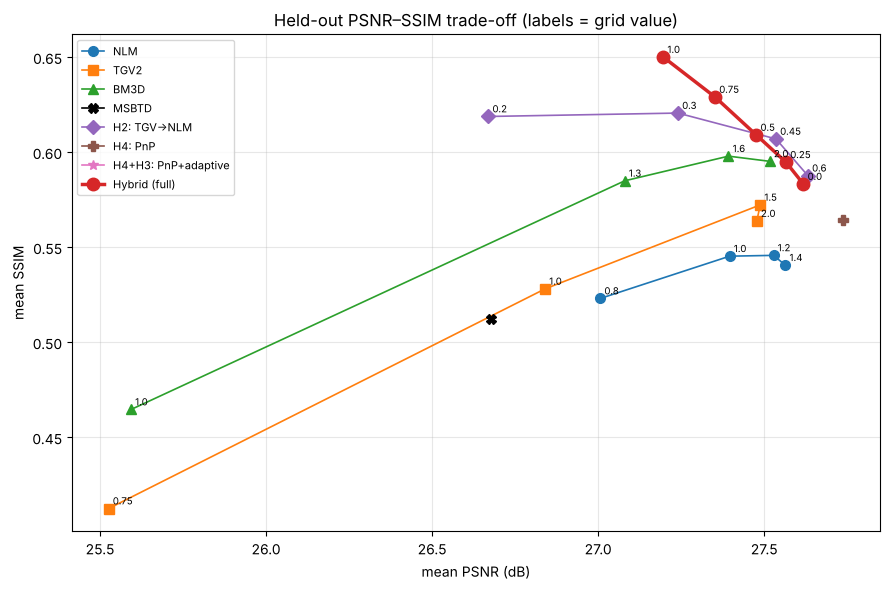

In [19]:
mean_grid = held.groupby(["method", "param"], sort=False)[["PSNR", "SSIM"]].mean().reset_index()
style = {"NLM": ("tab:blue", "o"), "TGV2": ("tab:orange", "s"), "BM3D": ("tab:green", "^"), "MSBTD": ("k", "X"),
         "H2: TGV→NLM": ("tab:purple", "D"), "H4: PnP": ("tab:brown", "P"), "H4+H3: PnP+adaptive": ("tab:pink", "*"),
         "Hybrid (full)": ("tab:red", "o")}
fig, ax = plt.subplots(figsize=(9, 6))
for m in ORDER:
    if m == "Noisy":
        continue
    g = mean_grid[mean_grid["method"] == m]
    c, mk = style[m]
    ax.plot(g["PSNR"], g["SSIM"], marker=mk, color=c, ms=9 if m.startswith("Hybrid") else 7,
            lw=2.5 if m.startswith("Hybrid") else 1.2, label=m)
    for _, r in g.iterrows():
        if len(g) > 1:
            ax.annotate(r["param"], (r["PSNR"], r["SSIM"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="mean PSNR (dB)", ylabel="mean SSIM", title="Held-out PSNR–SSIM trade-off (labels = grid value)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "pareto_psnr_ssim.png", dpi=120); plt.show()
mean_grid.to_csv(OUT_DIR / "heldout_grid_means.csv", index=False)

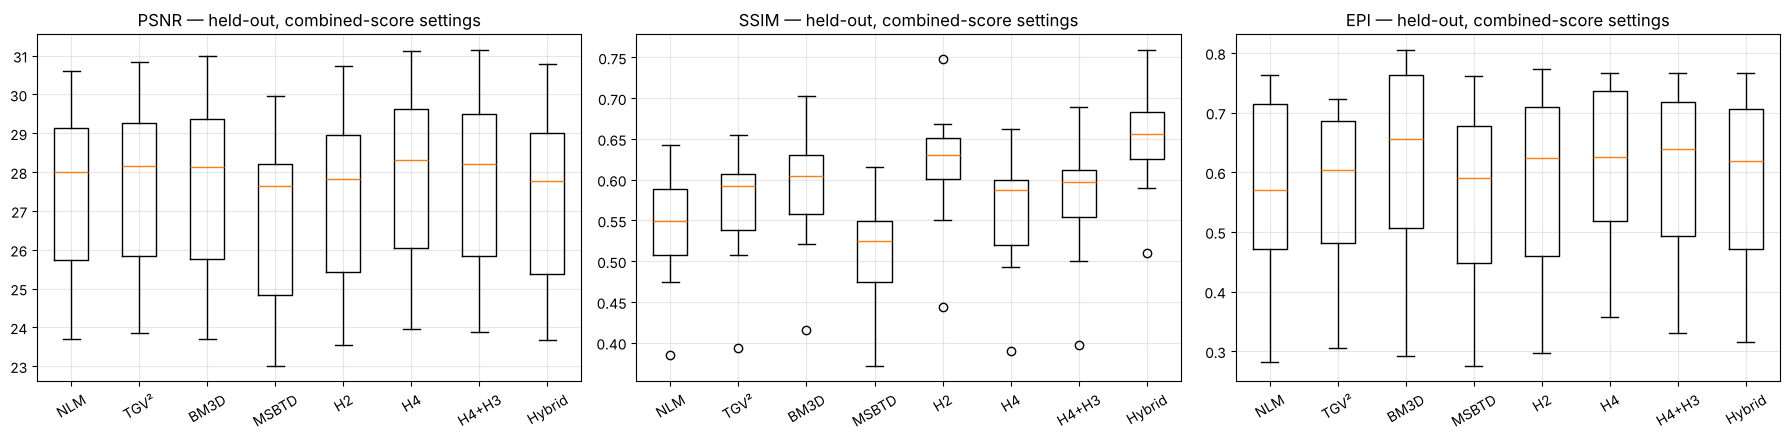

In [20]:
short = {"Noisy": "Noisy", "NLM": "NLM", "TGV2": "TGV²", "BM3D": "BM3D", "MSBTD": "MSBTD", "H2: TGV→NLM": "H2",
         "H4: PnP": "H4", "H4+H3: PnP+adaptive": "H4+H3", "Hybrid (full)": "Hybrid"}
order_nn = [m for m in ORDER if m != "Noisy"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, metric in zip(axes, ["PSNR", "SSIM", "EPI"]):
    ax.boxplot([res_m.loc[res_m["method"] == m, metric] for m in order_nn])
    ax.set_xticks(range(1, len(order_nn) + 1)); ax.set_xticklabels([short[m] for m in order_nn], rotation=30)
    ax.set_title(f"{metric} — held-out, combined-score settings"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "boxplots.png", dpi=110); plt.show()

### 10.5 Visual comparison

Two held-out B-scans at the combined-score settings, with a zoom on the outer retina and the absolute-error map
against the averaged image.

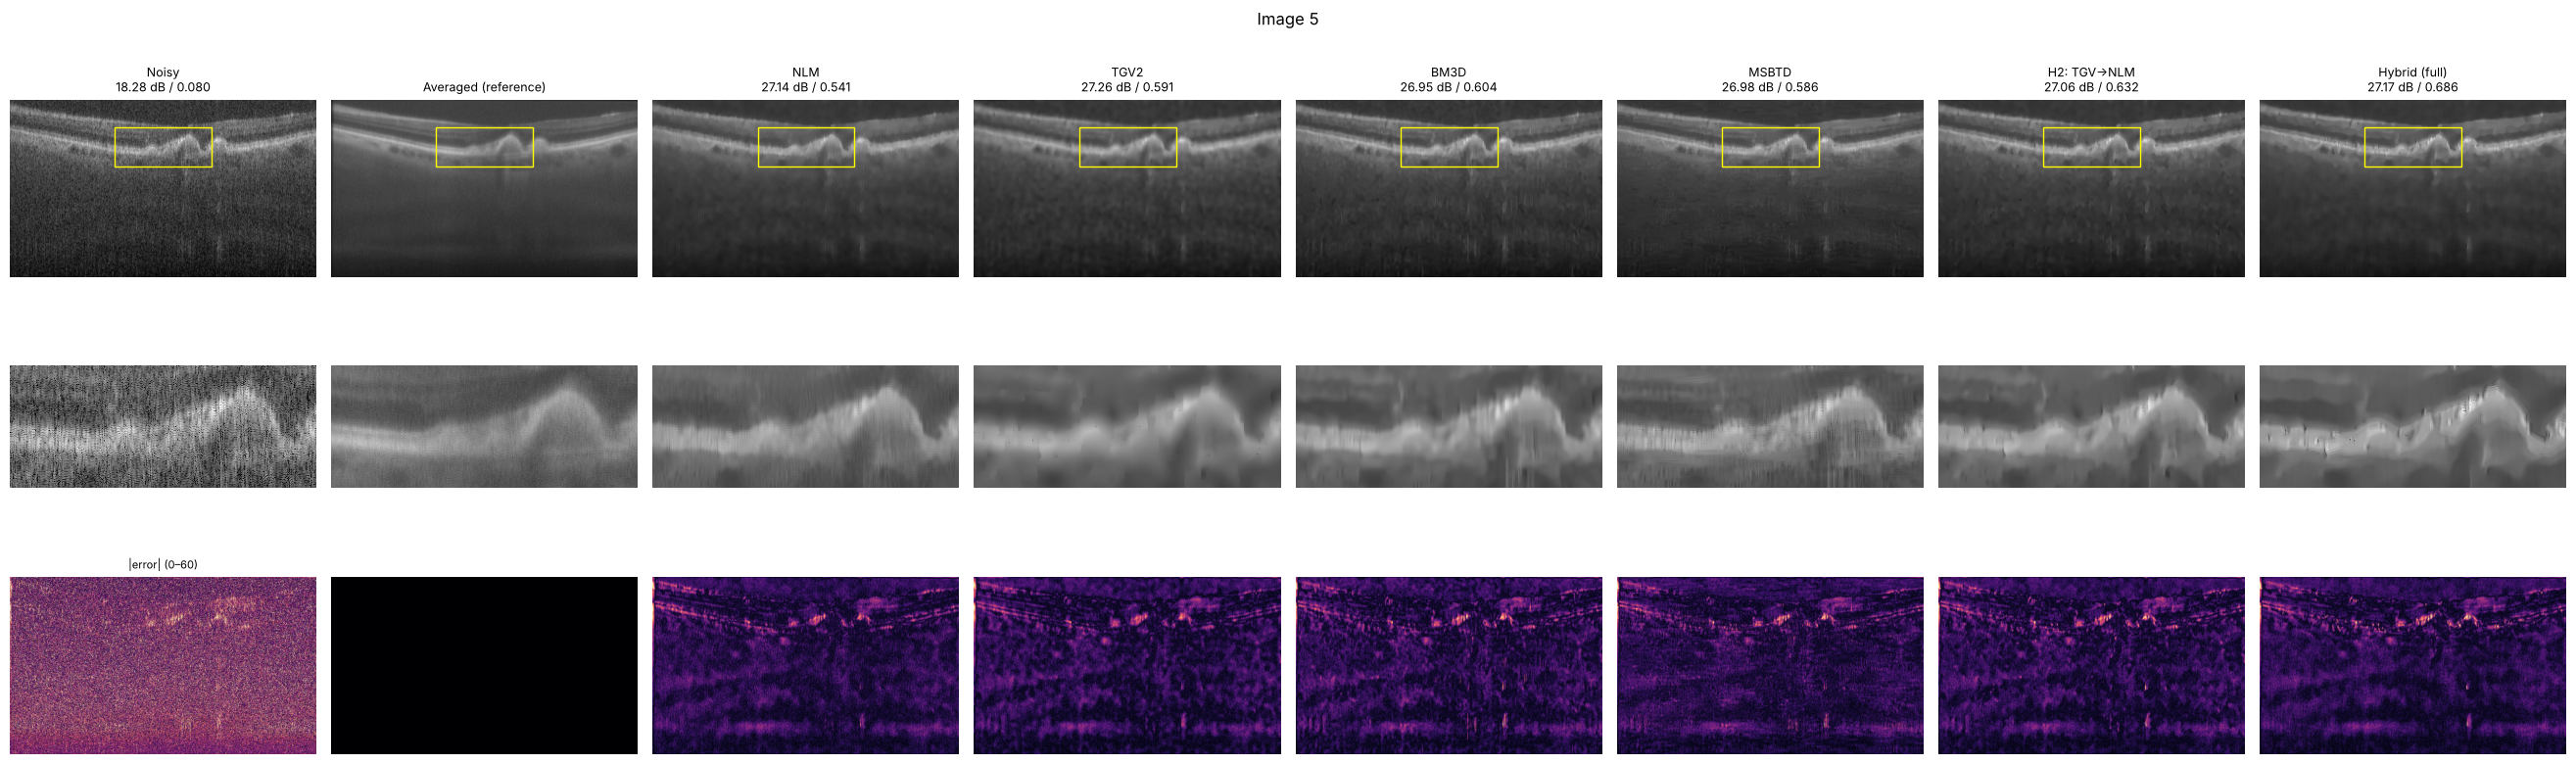

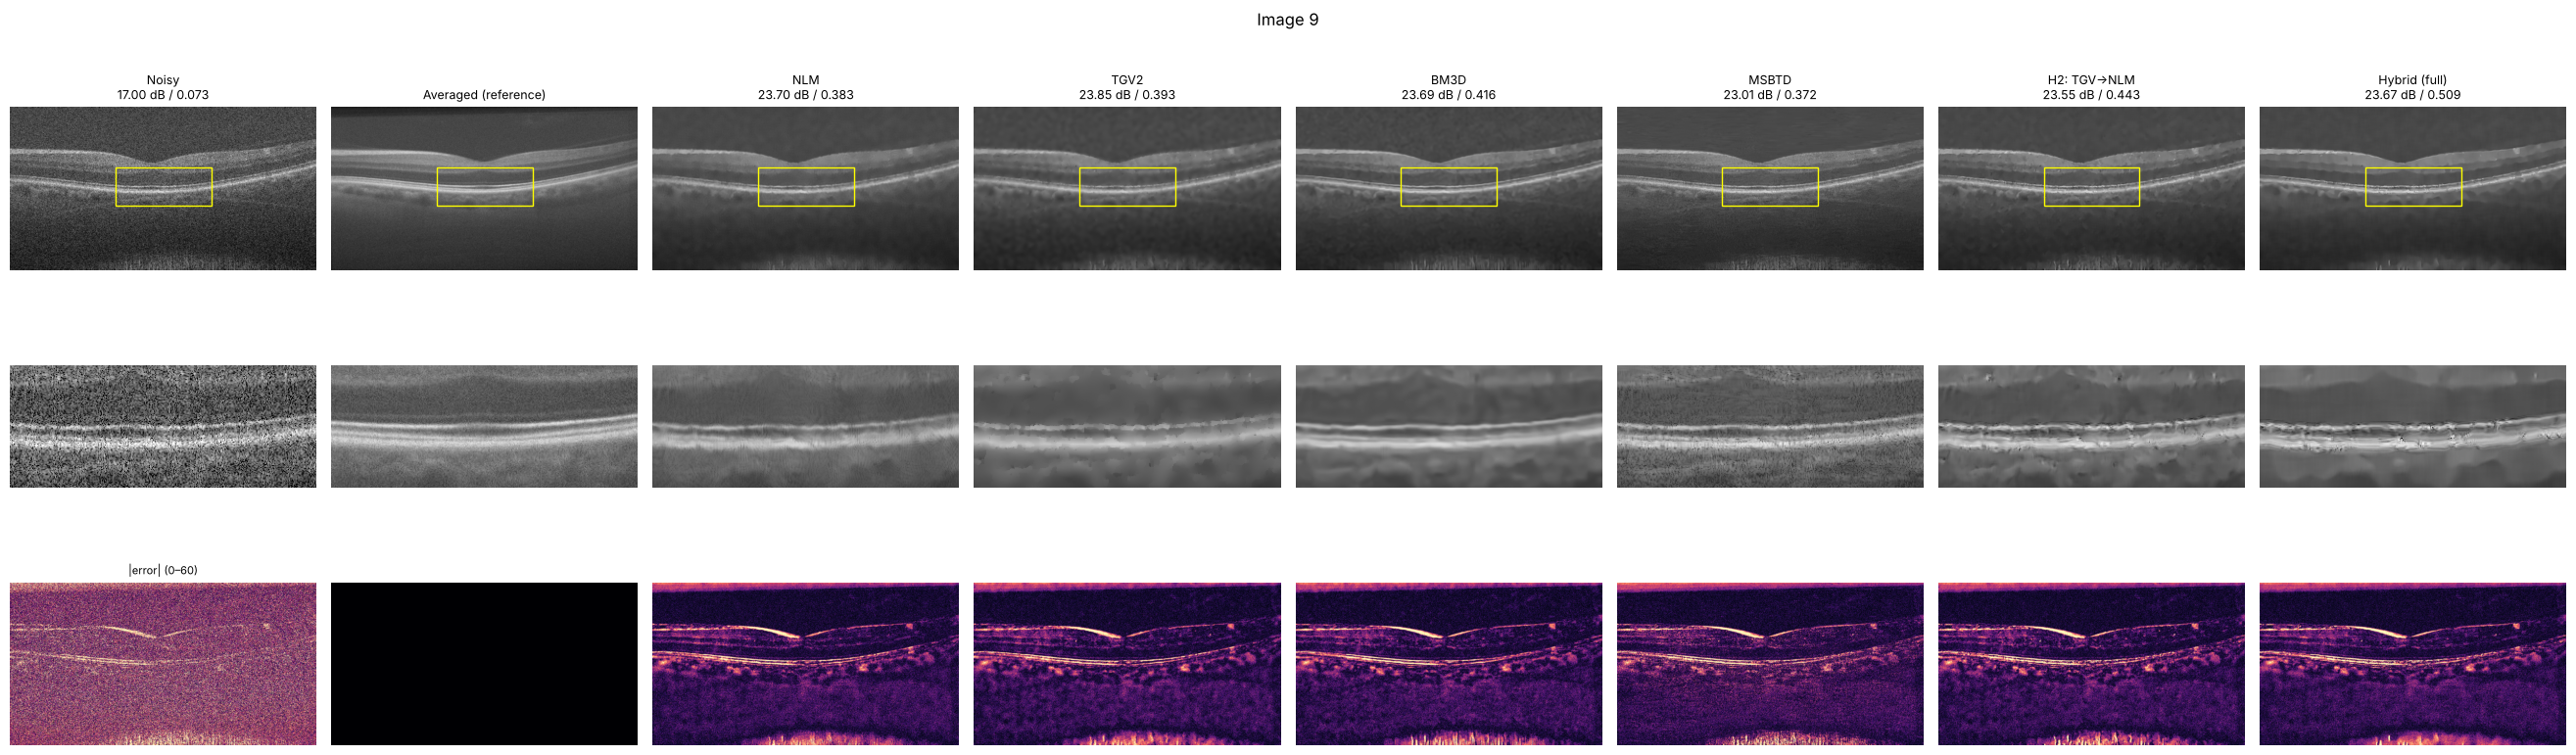

In [21]:
def load_saved(image, method, param):
    stem = f"{image.replace(' ', '_')}__{method.replace(' ', '').replace(':', '').replace('→', '-').replace('+', '_')}__{param}"
    p = OUT_DIR / "denoised" / f"{stem}.png"
    return load_gray(p) if p.exists() else None


SHOW = ["NLM", "TGV2", "BM3D", "MSBTD", "H2: TGV→NLM", "Hybrid (full)"]
for name in DEMO_IMAGES:
    r = images.set_index("image").loc[name]
    z, ref = load_gray(r["raw"]), load_gray(r["ref"])
    panels = [("Noisy", z), ("Averaged (reference)", ref)]
    for m in SHOW:
        im = load_saved(name, m, SEL_SCORE.get(m, "-")) if m != "MSBTD" else (load_msbtd(r["msbtd"]) if isinstance(r["msbtd"], Path) else None)
        if im is not None:
            panels.append((m, im))
    # zoom window centred on the brightest band (outer retina)
    cy = int(np.argmax(gaussian_filter(ref, 5).mean(axis=1)))
    zy = slice(max(cy - 60, 0), cy + 60); zx = slice(ref.shape[1] // 2 - 150, ref.shape[1] // 2 + 150)
    fig, axes = plt.subplots(3, len(panels), figsize=(3.3 * len(panels), 8.5))
    for j, (t, im) in enumerate(panels):
        sub = "" if t.startswith("Averaged") else f"\n{psnr(ref, im):.2f} dB / {ssim(ref, im):.3f}"
        axes[0, j].imshow(im, cmap="gray", vmin=0, vmax=MAX_VAL); axes[0, j].set_title(f"{t}{sub}", fontsize=9)
        axes[0, j].add_patch(plt.Rectangle((zx.start, zy.start), 300, zy.stop - zy.start, fill=False, ec="yellow"))
        axes[1, j].imshow(im[zy, zx], cmap="gray", vmin=0, vmax=MAX_VAL)
        axes[2, j].imshow(np.abs(im - ref), cmap="magma", vmin=0, vmax=60)
    for ax in axes.flat:
        ax.axis("off")
    axes[2, 0].set_title("|error| (0–60)", fontsize=8)
    fig.suptitle(name); plt.tight_layout()
    plt.savefig(OUT_DIR / f"visual_{name.replace(' ', '_')}.png", dpi=100); plt.show()

### 10.6 Result tracking

Each completed run appends one line per method to `outputs/run_history.csv` (timestamp, configuration, held-out
means), and `RESULTS.md` is regenerated with the current tables. Change a parameter, rerun with `USE_CACHE = False`
(or delete `results_log.csv`), and the history keeps both runs side by side.

In [22]:
stamp = dt.datetime.now().isoformat(timespec="seconds")
cfg_json = json.dumps(CONFIG, sort_keys=True)
hist = res_m.groupby("method")[["score", "PSNR", "SSIM", "EPI", "CNR", "ENL", "time_s"]].mean().loc[ORDER].reset_index()
hist.insert(0, "timestamp", stamp)
hist["param_score_sel"] = hist["method"].map(SEL_SCORE)
hist["param_psnr_sel"] = hist["method"].map(SEL_PSNR)
hist["param_ssim_sel"] = hist["method"].map(SEL_SSIM)
hist["param_epi_sel"] = hist["method"].map(SEL_EPI)
hist["config"] = cfg_json
hist_file = OUT_DIR / "run_history.csv"
hist.to_csv(hist_file, mode="a", header=not hist_file.exists(), index=False)

def md_table(df):
    df = df.reset_index()
    lines = ["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(map(str, r)) + " |" for r in df.values]
    return "\n".join(lines)

report = f'''# Hybrid PnP despeckling — latest results

Run: {stamp}  |  dataset: Duke SD-OCT 2012 (17 B-scans)  |  tuned on {", ".join(TUNE_IMAGES)}  |  reported on {len(HELD_OUT)} held-out B-scans

## Held-out means ± std, combined-score settings (main result; equal weights on normalised PSNR, SSIM, EPI)
{md_table(table_m)}

## Held-out means ± std, PSNR-selected settings
{md_table(table_p)}

## Held-out means ± std, SSIM-selected settings
{md_table(table_s)}

## Held-out means ± std, EPI-selected settings
{md_table(table_e)}

## Hybrid vs. each method (held-out, combined-score settings; Δ = hybrid − method)
{md_table(paired.round(4))}

Files: `results_log.csv` (every image × method × parameter), `run_history.csv` (one block per run),
`tuning_table.csv`, `selected_params.json`, `per_image_PSNR.csv`, `per_image_SSIM.csv`, figures `*.png`,
denoised images in `denoised/`.

Configuration: `{cfg_json}`
'''
(Path("RESULTS.md")).write_text(report, encoding="utf-8")
print(f"appended {len(hist)} rows to {hist_file}; wrote RESULTS.md")

appended 9 rows to outputs/run_history.csv; wrote RESULTS.md


## 11. Findings (run of 2026-11-03, 15 held-out B-scans, parameters picked on Images 1–2)

**1. PnP-ADMM (TGV² model step + NLM denoiser) gives the best PSNR of all methods.** `H4: PnP` reaches
**27.74 dB**: +0.22 dB over BM3D (15/15 images, p = 0.0001), +0.25 dB over TGV² (15/15), +0.17 dB over the best-PSNR
NLM (14/15) and +1.06 dB over MSBTD (15/15). It also keeps edges better than its two ingredients (EPI 0.608 vs
0.564 TGV², 0.558 NLM, 15/15 each), and is level with BM3D on edges (0.608 vs 0.616, p = 0.15). The ADMM trace shows
why it beats running TGV and NLM separately: the residual ‖x − v‖ drops ~10× and PSNR rises on every pass. The two
priors correct each other instead of one just smoothing the other's output.

**2. Stage 2 (patch matching on the PnP output, averaging of the raw scan) is a PSNR ↔ SSIM knob.** Going from β = 0
to β = 1 moves the held-out mean from 27.62 dB / 0.583 to 27.20 dB / **0.650**. That is the best SSIM of any method,
15/15 against every other method. EPI barely moves (0.598 → 0.586). On the PSNR–SSIM plot (§10.4), the hybrid's β
curve together with the TGV→NLM curve forms the upper-right edge: for any PSNR up to ~27.6 dB, no baseline gets more
SSIM.

**3. It does not beat BM3D on every metric.** With the combined score (equal weights on normalised PSNR, SSIM, EPI),
BM3D (c = 2.0) scores 0.875 and the full hybrid 0.861. The difference is not significant (hybrid ahead on 6/15,
p = 0.42). BM3D keeps thin bright bands best: EPI 0.616, and the hybrid loses on EPI on 14/15 images. In short, the
PnP variant wins on PSNR, the stage-2 variant wins on SSIM, and BM3D wins on edges.

**4. The intensity-adaptive map (Bernardes idea) did not generalise as an all-round gain.** On the tuning images it
helped PSNR, SSIM and EPI. On the held-out images it costs 0.12 dB PSNR (worse on 12/15) and gains 0.019 SSIM (15/15),
with EPI unchanged (p = 0.07). It is effectively a second SSIM knob. With only two tuning images, this is the kind of
effect that looks real during tuning and then does not transfer.

**5. Pilot-guided NLM (H2) is the cheapest big win.** Matching patches on a TGV pilot instead of the raw speckle
dominates plain NLM on every metric, at ~8 s per B-scan (vs ~35 s for PnP). Its held-out-best grid value (0.45) has
the second-highest combined score of all (0.865), but the tuning images picked 0.3 (0.811). With two tuning images,
selection noise is of the same size as the differences between the best methods.

**6. What drives the numbers.** Every decent method lands at 27.2–27.7 dB because the averaged image is not ground
truth. It has its own residual speckle, and its brightness differs from the raw scan by −6 to +7 grey levels
depending on the image. PSNR differences of 0.1–0.3 dB are only meaningful together with the paired
win counts, which is why §10.2 reports them.

**Limitations.** Duke 2012 only (17 B-scans, healthy and AMD-like). Tuning on 2 images. EPI uses a Laplacian of
Gaussian (σ = 2 px), so it is not directly comparable with papers that use a 3×3 Laplacian. No layer-segmentation
evaluation (the dataset has no layer labels). PnP takes ~35 s per B-scan in NumPy on 2 cores.

**Next steps, in order of expected payoff.**
1. **BM3D as the PnP denoiser (PnP-TGV-BM3D).** BM3D keeps edges best and PnP gives the best PSNR, so putting BM3D
   inside the ADMM loop is the natural combination of the two winners.
2. **FCFDS anisotropic kernel inside the PnP NLM step.** The Chen & Gao kernel failed on raw speckle. Inside PnP the
   patches are matched on a much cleaner image, which is where "don't mix across layers" should help the thin bands
   that every method currently flattens.
3. **More tuning images** (e.g. leave-one-out over the 17), to reduce the selection noise seen in finding 5.
4. **Segmentation-based evaluation** on a dataset with layer labels (e.g. Duke DME), to check whether the extra
   SSIM of stage 2 or the extra PSNR of PnP matters more for finding layer boundaries.